# Sentence embedding

Một học sinh gõ “quên thông tin đăng nhập” vào ô tìm kiếm, còn hướng dẫn cần tìm có tiêu đề “đặt lại mật khẩu”. Tìm theo từ khóa không ra, vì hai câu không chung từ nào. Sentence embedding biến mỗi câu thành một vector sao cho câu cùng ý có vector gần nhau, rồi tìm theo khoảng cách giữa các vector. Bài này học cách đo độ gần bằng cosine, cách gộp vector các token thành vector câu, cách model câu được huấn luyện, và cách chấm một hệ tìm kiếm.

> **Mục tiêu**
>
> - Tính cosine similarity; tìm kiếm bằng tích vô hướng sau khi chuẩn hóa.
> - Gộp vector token thành vector câu, bỏ qua PAD.
> - Chấm hệ tìm kiếm bằng Recall@k và MRR.
> - So TF-IDF với các loại sentence embedding.

## Một vector câu có ý nghĩa gì?

Ở bài 6.1, số chiều của TF-IDF bằng số mục trong vocabulary, mỗi chiều ứng với một từ. Sentence embedding dùng số chiều cố định $d$ do model quy định; từng chiều không nhất thiết có tên dễ đọc. Ký hiệu hàm mã hóa là $f(s)=\mathbf{e}\in\mathbb{R}^d$, với $s$ là câu. Hai câu được coi là gần nhau khi vector của chúng có hướng gần nhau trong không gian mà model đã học.

Có thể hình dung ba hướng “tài khoản”, “thư viện”, “lịch học”: đặt lại mật khẩu và khôi phục truy cập cùng nghiêng về hướng thứ nhất. Model thật có hàng trăm chiều và không chia nghĩa thành những nhãn tường minh như vậy. Không gian ấy do mục tiêu huấn luyện quyết định: lấy trung bình hidden state của một model chỉ học điền từ bị che không bảo đảm có một không gian tốt để tìm câu cùng ý. Mục “Model câu học từ cặp câu” cho thấy model được dạy điều đó ra sao.



Bài 4.2 đã dùng cosine để tìm ảnh gần nhau; với câu, phép đo giữ nguyên:

$$\operatorname{cos}(\mathbf{a},\mathbf{b})=\frac{\mathbf{a}^{\top}\mathbf{b}}{\lVert\mathbf{a}\rVert_2\lVert\mathbf{b}\rVert_2}.$$

Nó nằm trong $[-1,1]$ với hai vector khác 0. Cosine 1 là cùng hướng, 0 là vuông góc, $-1$ là ngược hướng. Không nên đọc 0.8 thành “80% xác suất đúng”: đây là một điểm tương tự, chưa được hiệu chuẩn thành xác suất. Với vector 0, góc không xác định; code phải phát hiện mẫu rỗng hoặc chọn quy ước xử lý rõ ràng.

In [ ]:
import numpy as np

def unit_rows(matrix):
    length = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(length, 1e-12)

query_hand = np.array([[1.0, 1.0]])
docs_hand = np.array([[2.0, 2.0], [1.0, 0.0], [-1.0, -1.0]])
scores_hand = unit_rows(query_hand) @ unit_rows(docs_hand).T
print(scores_hand.round(3))

[[ 1.     0.707 -1.   ]]


Điểm đầu là 1 dù vector tài liệu dài gấp đôi query: cosine chỉ nhìn hướng. Điểm thứ hai là $1/\sqrt2\approx0.707$ (góc 45°), điểm thứ ba là $-1$ (ngược hướng). Sau chuẩn hóa, cosine bằng tích vô hướng, nên với ma trận tài liệu $D$ shape `(N, d)` và query $\mathbf{q}$ shape `(d,)`, một phép nhân `D @ q` cho cả $N$ điểm. Nếu bỏ bước chuẩn hóa, tích vô hướng $\lVert\mathbf{a}\rVert\lVert\mathbf{b}\rVert\cos$ còn thưởng thêm cho vector dài. Một số model được huấn luyện đúng với score ấy; model card ghi model dùng hàm score nào, và lúc tìm kiếm phải dùng đúng hàm đó.

**Hỏi nhanh.** Hai vector $(1, 2)$ và $(3, 6)$ có cosine bằng bao nhiêu?

- A. 15
- B. 3
- C. 1
- D. 1/3

<details><summary>Đáp án</summary>

C. 1

$(3, 6) = 3\cdot(1, 2)$, nên hai vector cùng hướng, và cosine bằng 1. 15 là tích vô hướng, chưa chia cho tích độ dài $\sqrt5\cdot\sqrt{45} = 15$. 3 và 1/3 là tỉ số độ dài theo hai chiều, thứ mà cosine không đo.

</details>

**Hỏi nhanh.** Query là $\mathbf{q} = (1, 1)$. Tài liệu A là $(3, 0)$, tài liệu B là $(1, 1)$. Xếp theo tích vô hướng thô thì tài liệu nào đứng đầu? Xếp theo cosine thì sao?

- A. Theo tích vô hướng là A, theo cosine là B
- B. Theo tích vô hướng là B, theo cosine là B
- C. Theo tích vô hướng là A, theo cosine là A
- D. Theo tích vô hướng là B, theo cosine là A

<details><summary>Đáp án</summary>

A. Theo tích vô hướng là A, theo cosine là B

Tích vô hướng cho A là 3, cho B là 2. A thắng nhờ độ dài 3, dù lệch hướng 45°. Cosine cho A là $3/(3\sqrt2) \approx 0.707$, cho B là 1. B cùng hướng với query nên thắng. Hai cách xếp chắc chắn trùng nhau khi mọi tài liệu có cùng độ dài, chẳng hạn sau khi chuẩn hóa. Hai phương án còn lại đảo một trong hai kết quả vừa tính.

</details>



## Pooling phải biết token nào là thật

Encoder thường trả một vector cho mỗi token: hidden states $H$ có shape `(B, L, d)`, với $B$ là số câu trong batch, $L$ là độ dài sau padding. Ta cần một vector cho mỗi câu, shape `(B, d)`. Mean pooling lấy trung bình nhưng phải dùng mask $m_{bi}$: bằng 1 nếu vị trí có token được giữ, bằng 0 nếu là padding.

$$\mathbf{e}_b=\frac{\sum_{i=1}^{L}m_{bi}\mathbf{h}_{bi}}{\sum_{i=1}^{L}m_{bi}}.$$

Padding dùng để xếp câu dài ngắn vào cùng một tensor. Hidden state ở padding không được giả định luôn bằng 0; qua encoder, nó có thể khác 0. Nếu trung bình cả padding, vector câu sẽ phụ thuộc độ dài của những câu khác trong batch. Việc giữ hay bỏ special tokens trong pooling cũng theo recipe đã dùng khi huấn luyện model; không nên tự thay chỉ vì thấy `[CLS]` không phải từ bình thường.



Bài 4.2 đã viết phép tính này cho `last_hidden_state`; ở đây hàm `masked_mean` còn được dùng lại để huấn luyện ở mục sau. Hidden states được đặt tay để thấy riêng phép toán: hai token thật là $(2,0)$ và $(0,2)$, hai vị trí padding là $(9,9)$. Mean đúng bằng $(1,1)$, còn mean tính cả padding bị kéo về $(5,5)$.

In [ ]:
import torch

torch.set_num_threads(1)
hidden = torch.tensor([[[2., 0.], [0., 2.], [9., 9.], [9., 9.]]])
attention_mask = torch.tensor([[1, 1, 0, 0]])

def masked_mean(hidden_states, mask):
    weight = mask.unsqueeze(-1)
    weight = weight.to(hidden_states.dtype)
    token_count = weight.sum(dim=1).clamp_min(1)
    weighted_sum = (
        hidden_states * weight
    ).sum(dim=1)
    return weighted_sum / token_count

print("mean sai:", hidden.mean(dim=1).tolist())
print("mean đúng:", masked_mean(hidden, attention_mask).tolist())
print("shape:", tuple(masked_mean(hidden, attention_mask).shape))

mean sai: [[5.0, 5.0]]
mean đúng: [[1.0, 1.0]]
shape: (1, 2)


`unsqueeze(-1)` biến `(B, L)` thành `(B, L, 1)` để nhân cùng trọng số cho cả $d$ chiều. `clamp_min(1)` tránh chia 0, nhưng không khiến câu toàn padding có ý nghĩa; pipeline phải chặn đầu vào rỗng trước khi tìm kiếm.

**Hỏi nhanh.** Encoder đã ở `eval()` và nhận đủ `input_ids` lẫn `attention_mask`. Encode câu “mượn sách” một mình thì được vector $\mathbf{u}$. Encode nó chung batch với một câu dài hơn thì được $\mathbf{v}$, và $\cos(\mathbf{u}, \mathbf{v}) = 0.93$. Nguyên nhân khả dĩ nhất là gì?

- A. Dropout vẫn chạy, nên hai lần cho kết quả khác nhau
- B. Pooling lấy trung bình cả các vị trí padding
- C. float32 làm tròn khác nhau giữa hai batch
- D. Tokenizer tách “mượn sách” khác đi tùy theo batch

<details><summary>Đáp án</summary>

B. Pooling lấy trung bình cả các vị trí padding

Khi encoder nhận `attention_mask`, token thật không nhìn vào padding. Vì vậy hidden state của chúng gần như giống hệt, dù câu đi một mình hay đi chung batch. Chỉ khi pooling cộng cả các vị trí padding, vector câu mới bị kéo theo độ dài của câu kia. `eval()` đã tắt dropout. Sai số làm tròn float32 chỉ cỡ $10^{-6}$, không thể kéo cosine xuống 0.93. Tokenizer tách một câu cố định theo cùng một cách. Padding chỉ thêm vị trí đệm, không đổi token của câu.

</details>

**Hỏi nhanh.** Sau masked mean, pipeline luôn chuẩn hóa L2 rồi mới tính cosine. Trong `masked_mean`, một đội lỡ viết `token_count = weight.sum()`, tức tổng số token thật của cả batch, thay vì của từng câu. Thứ hạng retrieval thay đổi thế nào?

- A. Câu ngắn bị kéo về phía các vị trí padding
- B. Code báo lỗi shape, vì mẫu số chỉ còn một số vô hướng
- C. Mọi score cosine giảm theo số câu trong batch
- D. Thứ hạng không đổi, vì hướng của mỗi vector giữ nguyên

<details><summary>Đáp án</summary>

D. Thứ hạng không đổi, vì hướng của mỗi vector giữ nguyên

Tử số vẫn chỉ cộng token thật, nên hướng của mỗi vector câu không đổi. Chia cho số dương nào rồi chuẩn hóa L2 cũng cho cùng một vector đơn vị. Padding đã bị loại ở tử số, nên không kéo được câu ngắn. Chia tensor `(B, d)` cho một số là broadcasting hợp lệ, không báo lỗi. Cosine không phụ thuộc độ dài, nên không giảm theo cỡ batch. Mẫu số chỉ quan trọng khi vector chưa chuẩn hóa được dùng tiếp, như với tích vô hướng thô, hay với MSE và mục tiêu one-hot ở mục sau.

</details>

## Mốc từ vựng trước khi tìm theo nghĩa

Kho có ba tài liệu ngắn; ba query hỏi về đúng ba chủ đề ấy. Dấu gạch dưới nối các âm tiết của một từ để `split()` tách đúng từ, thay cho bước tách từ tiếng Việt ở bài 6.1. Query “quên truy_cập” dùng cách nói khác hẳn tài liệu “đặt_lại mật_khẩu”. Tài liệu đúng (gold) của từng query nằm trong `relevant`.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

documents = ["đặt_lại mật_khẩu", "mượn sách", "xem thời_khóa_biểu"]
queries = ["quên truy_cập", "mượn sách", "lịch học"]
relevant = np.array([0, 1, 2])

lexical = TfidfVectorizer(tokenizer=str.split, token_pattern=None)
document_tfidf = lexical.fit_transform(documents)
query_tfidf = lexical.transform(queries)
lexical_scores = (query_tfidf @ document_tfidf.T).toarray()
print(lexical_scores.round(3))

[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]


Hàng có toàn 0 không đưa ra bằng chứng tài liệu nào gần hơn: các từ của query đều ngoài vocabulary. Nếu `argmax` chọn tài liệu đầu tiên, đó chỉ là quy tắc phá hòa; không thể báo là hệ thống hiểu “quên truy cập”. Query trùng chữ “mượn sách” cho điểm 1. Baseline từ vựng này là mốc mà model embedding phải vượt trên những cách diễn đạt mới. Chiều ngược lại cũng xảy ra: khi query là một mã chính xác như lỗi “E1234”, tìm theo từ khóa thắng, còn embedding gom nó vào các bài nói chung về lỗi máy. Hệ thống thật thường ghép hai cách (hybrid search).

**Hỏi nhanh.** Thêm tài liệu thứ tư “đăng_ký học thêm” vào `documents`, rồi fit lại TF-IDF. Bây giờ query “lịch học” cho kết quả gì?

- A. Vẫn toàn 0, vì “lịch” không có trong vocabulary
- B. Tài liệu mới đứng đầu với 0.577, còn gold vẫn được 0
- C. Gold lên đầu, vì “học” gần nghĩa với “thời_khóa_biểu”
- D. Bốn tài liệu bằng điểm nhau, vì IDF chia đều

<details><summary>Đáp án</summary>

B. Tài liệu mới đứng đầu với 0.577, còn gold vẫn được 0

“học” giờ đã có trong vocabulary, nên query chỉ còn cột “học”, với độ dài 1. Tài liệu mới có ba từ, mỗi từ xuất hiện trong đúng một tài liệu, nên cùng IDF. Sau chuẩn hóa, mỗi cột là $1/\sqrt3 \approx 0.577$, và đó cũng là tích vô hướng với query. “xem thời_khóa_biểu” không chứa “học” nên vẫn được 0. TF-IDF không biết hai từ gần nghĩa nhau. “lịch” vẫn bị bỏ, nhưng chỉ cần một từ khớp là hàng đã khác 0. Kết quả là một tài liệu chung chữ nhưng khác ý đứng trên gold.

</details>

## Học một không gian nhỏ từ nhãn chủ đề

Muốn “quên truy_cập” gần “đặt_lại mật_khẩu”, biểu diễn phải học được rằng các từ khác chữ có thể cùng ý. Thí nghiệm nhỏ nhất làm được việc đó có chín câu train thuộc ba chủ đề; mỗi câu có vector mục tiêu one-hot ba chiều, chẳng hạn chủ đề tài khoản là $(1,0,0)$. Một bảng embedding token ba chiều, khởi tạo ngẫu nhiên, cho mỗi câu vector bằng masked mean của các token; MSE kéo vector câu về mục tiêu của chủ đề. Đây là encoder nhỏ nhất có thể: không attention, không ngữ cảnh, học trong vài giây, nhưng đi đúng đường của model thật: token thành vector, pooling có mask, chuẩn hóa rồi so cosine.

In [ ]:
torch.manual_seed(6)
train_sentences = [
    "đặt_lại mật_khẩu", "quên mật_khẩu", "khôi_phục truy_cập",
    "mượn sách", "thẻ thư_viện", "gia_hạn sách",
    "xem thời_khóa_biểu", "lịch học", "buổi học",
]
topic = torch.tensor([0, 0, 0, 1, 1, 1, 2, 2, 2])
vocabulary = {word: i + 1 for i, word in enumerate(
    sorted({word for sentence in train_sentences for word in sentence.split()})
)}

def encode_batch(sentences):
    token_lists = [[vocabulary.get(word, 0) for word in sentence.split()] for sentence in sentences]
    max_length = max(len(tokens) for tokens in token_lists)
    ids = torch.zeros(len(sentences), max_length, dtype=torch.long)
    for row, tokens in enumerate(token_lists):
        ids[row, :len(tokens)] = torch.tensor(tokens)
    return ids, ids.ne(0)

embedding = torch.nn.Embedding(len(vocabulary) + 1, 3, padding_idx=0)
optimizer = torch.optim.Adam(embedding.parameters(), lr=0.05)
train_ids, train_mask = encode_batch(train_sentences)
target_vectors = torch.nn.functional.one_hot(topic, 3).float()
history = []
for step in range(160):
    optimizer.zero_grad()
    sentence_vectors = masked_mean(embedding(train_ids), train_mask)
    loss = torch.nn.functional.mse_loss(sentence_vectors, target_vectors)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
print("MSE đầu/cuối:", round(history[0], 4), round(history[-1], 4))

MSE đầu/cuối: 0.7867 0.0


MSE về 0.0 (làm tròn bốn chữ số) nghĩa là mean vector của mọi câu train gần như trùng mục tiêu; đó là phép đo trên train, chưa phải metric retrieval. ID 0 dùng chung cho padding và từ chưa gặp, nên từ lạ bị loại khỏi mean. Query chỉ gồm từ lạ thành rỗng, và `encode_small` dưới đây dừng với lỗi thay vì trả một tài liệu tùy ý. Tokenizer subword ở bài 6.1 tránh tình huống này bằng cách ghép từ lạ từ những mảnh quen.

Ta encode documents và queries bằng cùng bảng, chuẩn hóa rồi tìm điểm lớn nhất.

In [ ]:
def encode_small(sentences):
    ids, mask = encode_batch(sentences)
    if not torch.all(mask.any(dim=1)):
        raise ValueError("Có câu không chứa token đã biết")
    with torch.no_grad():
        vectors = masked_mean(embedding(ids), mask).numpy()
    return unit_rows(vectors)

document_vectors = encode_small(documents)
query_vectors = encode_small(queries)
learned_scores = query_vectors @ document_vectors.T
print(learned_scores.round(3))
print("top-1:", learned_scores.argmax(axis=1).tolist())

[[ 0.845  0.211 -0.491]
 [-0.     1.    -0.   ]
 [-0.     0.     1.   ]]
top-1: [0, 1, 2]


Hàng đầu là query đáng xem nhất: “quên truy_cập” không có nguyên câu trong train, nhưng cả hai token đều thuộc nhóm tài khoản, và tài liệu mật khẩu đứng đầu với 0.845. Hai hàng còn lại cho điểm 1 tròn vì cả query lẫn tài liệu đúng của chúng đều là câu train, và MSE đã đặt mean của mọi câu train cùng chủ đề vào cùng một điểm; hai query này chỉ kiểm việc nhớ lại. Một query mới chưa đủ để biết bảng đã học gì. Ta xem vector của hai từ trong câu train “quên mật_khẩu”, rồi thử hai cách ghép chưa có trong train.



In [ ]:
def word_vector(word):
    return embedding.weight[vocabulary[word]].detach().numpy()

forget, password = word_vector("quên"), word_vector("mật_khẩu")
print("quên:", forget.round(2))
print("mật_khẩu:", password.round(2))
print("trung bình:", ((forget + password) / 2).round(2) + 0.0)
held_out = ["khôi_phục mật_khẩu", "quên thẻ thư_viện"]
print((encode_small(held_out) @ document_vectors.T).round(3))

quên: [ 0.95  0.41 -0.66]
mật_khẩu: [ 1.05 -0.41  0.66]
trung bình: [1. 0. 0.]
[[ 0.725 -0.272  0.633]
 [ 0.357  0.901 -0.248]]


Thành phần đầu của “quên” và “mật_khẩu” cộng lại bằng 2, còn thành phần thứ hai và thứ ba đối dấu nhau, nên trung bình rơi đúng $(1,0,0)$. MSE chỉ ràng buộc trung bình của từng câu train, không ràng buộc từng từ; phần dư của mỗi từ được phép lớn, miễn là triệt tiêu trong câu train. Ghép “khôi_phục” với “mật_khẩu”, hai từ chưa từng đứng cùng câu, thì phần dư không còn triệt tiêu: query vẫn chọn tài liệu mật khẩu (0.725) nhưng tài liệu lịch học bám sát ở 0.633. “quên thẻ thư_viện” có hai từ ghép thành câu train “thẻ thư_viện”, cùng với “quên” của nhóm tài khoản; ở seed này mean nghiêng về thư viện (0.901), đúng với ý của câu. Phần dư phụ thuộc khởi tạo: đổi `torch.manual_seed(6)` thành `torch.manual_seed(0)` rồi chạy lại, cả hai query ghép đều chọn sai tài liệu. Hai câu “An giúp Bình” và “Bình giúp An” vẫn có cùng mean vì bảng token không nhìn thứ tự. Một model câu thật cần ngữ cảnh, nhiều dữ liệu hơn và một mục tiêu so sánh trực tiếp các câu với nhau.



**Hỏi nhanh.** Trong train, `đặt_lại` cũng chỉ xuất hiện trong một câu, cùng với `mật_khẩu`, với mục tiêu $(1, 0, 0)$. Khi MSE về gần 0, vector của `đặt_lại` gần với vector nào nhất?

- A. Vector $(1, 0, 0)$, đúng mục tiêu của chủ đề
- B. Vector của `mật_khẩu`, từ đi cùng nó trong câu
- C. Vector của `quên`, khoảng $(0.95, 0.41, -0.66)$
- D. Không đoán được, vì mỗi hàng giữ khởi tạo riêng

<details><summary>Đáp án</summary>

C. Vector của `quên`, khoảng $(0.95, 0.41, -0.66)$

MSE gần 0 buộc trung bình của “đặt_lại mật_khẩu” và của “quên mật_khẩu” cùng bằng $\mathbf{t} = (1, 0, 0)$. Vì vậy cả `đặt_lại` lẫn `quên` đều phải bằng $2\mathbf{t} - \mathbf{v}_{\text{mk}}$, với $\mathbf{v}_{\text{mk}}$ là vector của `mật_khẩu`. Dữ liệu không bao giờ phân biệt hai từ, nên bảng coi chúng như nhau, dù “quên” và “đặt lại” không cùng nghĩa. Ràng buộc đặt lên trung bình câu chứ không lên từng từ, nên từ không tự bằng $(1, 0, 0)$. Nó cũng không bằng `mật_khẩu`, vì khi đó trung bình là chính `mật_khẩu`. Khởi tạo riêng của hai hàng không còn quyết định gì: khi trung bình câu đã khớp mục tiêu, `quên` và `đặt_lại` bị xác định hoàn toàn bởi `mật_khẩu`.

</details>

## Đo thứ hạng

Nếu mỗi query có đúng một tài liệu liên quan, Recall@k là tỉ lệ query có tài liệu ấy trong top $k$. Reciprocal rank là nghịch đảo thứ hạng của tài liệu đúng, và MRR (mean reciprocal rank) là trung bình các nghịch đảo đó: đúng ở hạng 1 đóng góp 1, ở hạng 3 đóng góp $1/3$. Khi nhiều tài liệu cùng liên quan, phải định nghĩa gold set và metric phù hợp; không ép chúng vào một ID tùy tiện. Với một hệ thống RAG trả lời sai, đo Recall@k của bước tìm tài liệu trước tiên: đoạn đúng không có trong top $k$ thì model ngôn ngữ dù tốt cũng không có gì để dựa vào.

In [ ]:
def retrieval_metrics(scores, gold):
    # stable giúp quy tắc phá hòa được xác định, không tạo thêm bằng chứng.
    order = np.argsort(-scores, axis=1, kind="stable")
    rank = np.array([np.flatnonzero(row == correct)[0] + 1
                     for row, correct in zip(order, gold)])
    return (rank == 1).mean(), (1 / rank).mean(), rank

for name, scores in [("TF-IDF", lexical_scores), ("embedding nhỏ", learned_scores)]:
    recall, mrr, ranks = retrieval_metrics(scores, relevant)
    print(name, "rank:", ranks.tolist(), "R@1:", round(recall, 3), "MRR:", round(mrr, 3))

TF-IDF rank: [1, 1, 3] R@1: 0.667 MRR: 0.778
embedding nhỏ rank: [1, 1, 1] R@1: 1.0 MRR: 1.0


TF-IDF có thứ hạng `[1, 1, 3]`. Query đầu toàn điểm 0 nhưng vẫn được tính hạng 1, chỉ vì tài liệu đúng nằm ở chỉ số 0 và sắp xếp `stable` giữ thứ tự gốc khi hòa. R@1 0.667 vì thế chứa một lần trúng nhờ phá hòa; báo metric phải kèm điểm, và đếm riêng những hàng toàn 0. Embedding nhỏ đạt R@1 và MRR cùng bằng 1.0, nhưng hai trong ba query là chính câu train.



**Hỏi nhanh.** Giữ nguyên query và điểm TF-IDF, chỉ xếp lại kho thành [“mượn sách”, “xem thời_khóa_biểu”, “đặt_lại mật_khẩu”]. R@1 và MRR của TF-IDF thành bao nhiêu?

- A. R@1 khoảng 0.333, MRR khoảng 0.611
- B. R@1 khoảng 0.667, MRR khoảng 0.778
- C. R@1 khoảng 0.333, MRR khoảng 0.778
- D. R@1 khoảng 0.667, MRR khoảng 0.611

<details><summary>Đáp án</summary>

A. R@1 khoảng 0.333, MRR khoảng 0.611

“mượn sách” vẫn có điểm 1, nên giữ hạng 1. Hai query toàn 0 giữ thứ tự của kho. Gold của “quên truy_cập” giờ ở chỉ số 2, tức hạng 3, còn gold của “lịch học” ở chỉ số 1, tức hạng 2. Thứ hạng `[3, 1, 2]` cho R@1 bằng $1/3$ và MRR bằng $(1/3 + 1 + 1/2)/3 \approx 0.611$. Không có thông tin gì mới, vậy mà metric vẫn đổi: phần thay đổi đến từ thứ tự lưu tài liệu. 0.667 và 0.778 là số cũ, chỉ đúng với thứ tự cũ. Hai phương án còn lại chỉ đổi một trong hai số.

</details>

Một bộ đánh giá retrieval có ích cần ba thứ mà ba query này chưa có. Query phải do người khác viết, không chép từ train. Kho phải có hard negatives: tài liệu chung nhiều chữ với query nhưng trả lời việc khác, như “gia_hạn thẻ thư_viện” và “làm_lại thẻ thư_viện”. Và cách chia phải giống lúc dùng: nếu đề chấm trên những FAQ chưa xuất hiện lúc train, mọi cách hỏi của cùng một FAQ phải nằm cùng một phía. Chia ngẫu nhiên theo từng câu hỏi thì các cách hỏi gần trùng của một FAQ có mặt ở cả hai phía, và validation chỉ đo việc nhận lại.

## Model câu học từ cặp câu

Bảng nhỏ ở trên học từ nhãn chủ đề, nên chỉ biết ba hướng. Model câu được fine-tune trên cặp câu: Sentence-BERT gốc dùng cặp có nhãn suy luận (NLI), các model về sau thêm câu với bản diễn đạt lại, câu hỏi với câu trả lời. Với model dùng để tìm kiếm, mục tiêu phổ biến không còn là một vector cố định cho mỗi lớp mà là so sánh: cặp đúng phải có score cao hơn các cặp sai, và chính các cặp khác trong batch làm negative. Với $B$ cặp $(\mathbf{q}_i,\mathbf{p}_i)$ đã chuẩn hóa,

$$\mathcal{L}=-\frac1B\sum_{i=1}^{B}\log\frac{\exp(\mathbf{q}_i^{\top}\mathbf{p}_i/\tau)}{\sum_{j=1}^{B}\exp(\mathbf{q}_i^{\top}\mathbf{p}_j/\tau)}.$$

Mỗi hàng là một bài phân loại $B$ lớp mà lớp đúng là tài liệu của chính cặp đó; $B-1$ tài liệu còn lại là in-batch negatives. Nhiệt độ $\tau$ nhỏ làm softmax nhọn hơn. Đây là cùng dạng loss của CLIP ở bài 4.5 và SimCLR ở bài 5.7, chỉ khác hai phía đều là câu; thư viện Sentence Transformers gọi nó là `MultipleNegativesRankingLoss`. Loss đòi tài liệu đúng đứng trên các tài liệu khác, đúng điều Recall@k và MRR đo, nhưng nó khả vi theo tham số, còn hai metric thứ hạng thì không. Model kiểu này là bi-encoder: câu hỏi và tài liệu được mã hóa riêng, nên vector tài liệu tính sẵn một lần và tìm trong một triệu đoạn chỉ còn là phép nhân ma trận. Cross-encoder đưa cả cặp vào một model để chấm trực tiếp, chính xác hơn nhưng phải chạy lại cho từng cặp; thường dùng nó để xếp lại vài chục ứng viên đầu do bi-encoder tìm ra.



Negative lấy ngẫu nhiên thường quá dễ: phân biệt “mượn sách” với “xem thời_khóa_biểu” không dạy model điều gì mới. Hard negative là tài liệu chung chữ hoặc chủ đề với query nhưng không trả lời nó, được thêm làm một cột cho mỗi hàng. Nó phải thật sự sai. Nếu “hard negative” là một bản diễn đạt khác của tài liệu đúng, loss sẽ đẩy query ra xa chính câu trả lời của nó (false negative). Lỗi cùng loại xảy ra khi hai cặp trong một batch có chung tài liệu đúng.

**Hỏi nhanh.** Khi train bằng contrastive loss, mỗi query được thêm một hard negative. Query “đổi mật khẩu” có tài liệu đúng là “Hướng dẫn đặt lại mật khẩu”. Nên chọn hard negative nào?

- A. “Cách mượn sách thư viện”, khác hẳn chủ đề
- B. Một tài liệu ngẫu nhiên khác trong kho
- C. “Các bước đổi mật khẩu tài khoản”, chung nhiều chữ nhất
- D. “Hướng dẫn đổi lịch học”, chung chữ “đổi” nhưng khác việc

<details><summary>Đáp án</summary>

D. “Hướng dẫn đổi lịch học”, chung chữ “đổi” nhưng khác việc

Hard negative có ích phải vừa dễ nhầm, vừa thật sự sai. “Đổi lịch học” chung chữ “đổi” nhưng trả lời một việc khác, buộc model nhìn vào ý chứ không chỉ nhìn chữ. “Các bước đổi mật khẩu tài khoản” chung nhiều chữ nhất, nhưng cũng trả lời đúng query. Đẩy nó ra xa là dạy model điều sai, gọi là false negative. Tài liệu mượn sách hay một tài liệu ngẫu nhiên đã khác xa query, nên xác suất softmax của chúng gần 0, và gần như không cho gradient.

</details>

## Dùng model pretrained

[Recipe sentence embedding](recipes/sentence_embedding.py) chạy lại đúng thí nghiệm tìm kiếm của bài với model `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`. Ba tài liệu và ba query được viết thành câu tiếng Việt đầy đủ, không cần gạch dưới: “Hướng dẫn đặt lại mật khẩu” đi với “Tôi quên thông tin đăng nhập”, và tương tự cho mượn sách, lịch học. Recipe dùng tokenizer của model, masked mean pooling và chuẩn hóa L2, rồi in ma trận điểm $3\times3$ và top-1 dưới dạng JSON, kèm revision của model và phiên bản thư viện. Trước khi encode, nó đọc `1_Pooling/config.json` để chắc snapshot dùng mean pooling, đọc `max_seq_length` trong `sentence_bert_config.json` và dừng nếu có câu dài hơn, thay vì để tokenizer cắt âm thầm. Recipe không tải gì từ Internet; [hướng dẫn asset](recipes/README.md) nêu yêu cầu với snapshot local: manifest có commit, SHA-256 của từng file và license đã đọc. Ma trận điểm được đọc như hai baseline: hàng là query, cột là tài liệu. Hàng “Tôi quên thông tin đăng nhập” cho biết model có đưa tài liệu mật khẩu lên đầu khi hai bên không chung chữ hay không, và khoảng cách giữa điểm cao nhất với điểm thứ hai cho biết lựa chọn ấy chắc đến đâu.

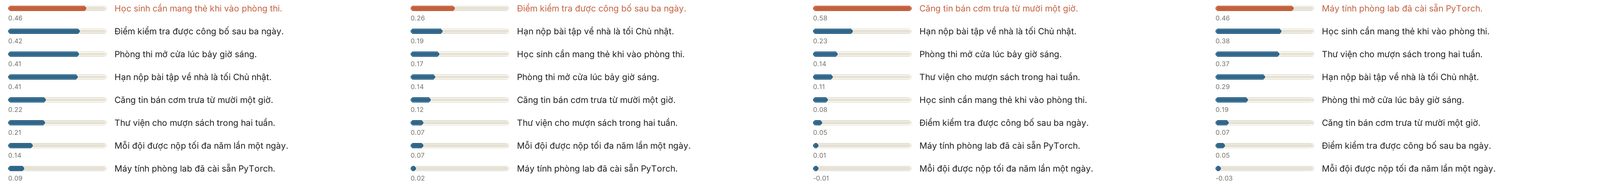

Với kho lớn, tài liệu được encode một lần theo batch rồi lưu cache kèm model, revision, tokenizer, pooling và chuẩn hóa; đổi một thành phần là phải encode lại. Tài liệu dài hơn độ dài tối đa được chia thành đoạn, có thể chồng lên nhau một phần để câu trả lời không bị cắt đôi. Mỗi đoạn có điểm riêng, và điểm của tài liệu được gộp từ điểm các đoạn theo một quy tắc ghi rõ. Tìm kiếm brute force là một phép nhân ma trận: kho $100\,000$ đoạn, mỗi đoạn 384 số `float32`, chiếm $100\,000\times384\times4$ byte $\approx154$ MB, và mỗi query tốn khoảng $Nd\approx3.8\times10^{7}$ phép nhân–cộng. Đó là mốc đúng để đối chiếu; chỉ chuyển sang tìm kiếm gần đúng khi đã đo được brute force quá chậm, và khi ấy phải đo phần recall bị mất. Ngưỡng score và $k$ chọn bằng validation: cosine không có ngưỡng chung cho mọi model.

**Hỏi nhanh.** Tài liệu nội quy thư viện dài 40 đoạn, mỗi đoạn được encode riêng. Chỉ đoạn 17 trả lời query “mất thẻ thì làm gì”. Nên gộp điểm của cả tài liệu thế nào?

- A. Lấy trung bình điểm của 40 đoạn cho công bằng
- B. Lấy điểm lớn nhất trong 40 đoạn
- C. Chỉ encode đoạn đầu, vì đoạn đầu thường tóm tắt
- D. Nối 40 đoạn lại, để tokenizer tự cắt

<details><summary>Đáp án</summary>

B. Lấy điểm lớn nhất trong 40 đoạn

Chỉ cần một đoạn trả lời là tài liệu đã liên quan, nên điểm lớn nhất giữ được tín hiệu của đoạn 17. Đoạn ấy cũng là thứ nên hiển thị cho người hỏi. Lấy trung bình thì một đoạn tốt bị pha loãng giữa 39 đoạn không liên quan, và một tài liệu dài mà đúng có thể thua một tài liệu ngắn mà sai. Chỉ encode đoạn đầu, hay nối lại để tokenizer cắt, đều làm mất đúng đoạn 17 mà không báo lỗi.

</details>



## Phản hồi gần nghĩa: đoán từ theo score

Một dạng bài tương tác: chương trình đoán một từ, judge trả về độ gần nghĩa giữa từ đoán và từ bí mật, lặp đến khi trúng hoặc hết lượt. Bài 8.3 phân tích một đề thi thật dạng này. Embedding cho một cách dự đoán phản hồi: nếu từ bí mật là $h$, đoán $g$ sẽ nhận score xấp xỉ $\cos(\mathbf{e}_g,\mathbf{e}_h)$. Chiến lược là giữ một tập ứng viên. Sau mỗi lượt, giữ lại những ứng viên $h$ có $\cos(\mathbf{e}_g,\mathbf{e}_h)$ gần score nhận được, trong một sai số cho phép, vì embedding của judge có thể khác embedding công khai. Lượt tiếp theo chọn từ mà các ứng viên còn lại cho score khác nhau nhiều nhất, để một phản hồi loại được nhiều ứng viên nhất. Lịch sử từ đã đoán và score được giữ lại để không thử lại cùng một hướng.

Score không phải khoảng cách đường đi cộng được, và embedding là một phép đo đã học: nó có thể ưu tiên chủ đề hơn quan hệ logic. “Có học” và “không học” có thể gần nhau vì xuất hiện trong những ngữ cảnh giống nhau, dù trái nghĩa. Quan hệ logic giữa hai câu (kéo theo, mâu thuẫn, trung lập) là một nhiệm vụ riêng, natural language inference (NLI), học bằng nhãn trên từng cặp câu.

**Hỏi nhanh.** Còn ba ứng viên A, B, C cho từ bí mật. Score của judge lệch tối đa $\pm 0.05$ so với cosine tính theo embedding công khai. Mỗi phương án dưới đây là một từ có thể đoán, kèm cosine dự đoán với A, B và C. Đoán từ nào thì chỉ một lần phản hồi là chắc chắn còn lại đúng một ứng viên?

- A. G1, với 0.50, 0.50, 0.50
- B. G2, với 0.90, 0.88, 0.20
- C. G3, với 0.80, 0.45, 0.10
- D. G4, với 0.95, 0.94, 0.93

<details><summary>Đáp án</summary>

C. G3, với 0.80, 0.45, 0.10

Với G3, ba khoảng $0.80 \pm 0.05$, $0.45 \pm 0.05$ và $0.10 \pm 0.05$ tách rời nhau. Score nhận được rơi vào đúng một khoảng, và chỉ ra một ứng viên. G1 cho cùng score với cả ba, không loại được ai. G2 tách được C, nhưng A và B chỉ chênh 0.02, nằm trong sai số. G4 có vẻ hấp dẫn vì gần cả ba ứng viên, nhưng chính vì gần đều nên phản hồi của nó không phân biệt được ai.

</details>



## Khi đi thi

- **Dựng mốc TF-IDF trước.** Chỉ mất vài phút, và query trùng mã môn, tên riêng hay số hiệu thường được TF-IDF xếp đúng hơn embedding. Embedding phải vượt mốc này trên validation mới đáng giữ; trộn điểm hai bên cũng là một lựa chọn cần đo.
- **Viết hàm chấm giống hệt đề.** Recall@k hay MRR@k, $k$ bằng bao nhiêu, query không có tài liệu đúng trong top-$k$ tính ra sao; in thứ hạng từng query trên validation chứ không chỉ một con số.
- **Validation giống lúc chấm.** Query do người khác viết, chia theo nhóm FAQ khi đề chấm trên tài liệu mới, kho có hard negatives. Điểm chỉ so được giữa các model trên cùng một kho.
- **Theo đúng cấu hình model.** Pooling, chuẩn hóa và hàm score lấy từ model card hoặc snapshot; câu dài hơn độ dài tối đa thì chia đoạn thay vì để bị cắt.
- **Dự toán thời gian encode.** Đo thời gian một batch, nhân lên cho cả kho trước khi chạy; encode kho một lần, query theo batch, brute force bằng một phép nhân ma trận.
- **Kiểm file nộp.** Mỗi query đủ $k$ ID, không trùng, xếp theo score giảm dần, và là ID gốc của tài liệu chứ không phải chỉ số hàng sau khi lọc hay sắp lại.

## Tóm tắt

- Embedding cho mỗi câu một vector cố định; không gian có ích hay không do mục tiêu huấn luyện quyết định.
- Cosine so hướng: chuẩn hóa L2 rồi lấy tích vô hướng. Vector 0 cần xử lý riêng.
- Mean pooling chỉ cộng token thật; hidden state ở padding không được coi là bằng 0.
- Model câu học từ cặp câu bằng contrastive loss với in-batch negatives; hard negative có ích khi chung chữ mà thật sự sai.
- Retrieval cần gold, metric thứ hạng, query độc lập và cách chia giống lúc chấm. Gần nghĩa không đồng nhất với quan hệ logic.

## Kiểm tra cuối bài

**Câu 1.** `vectors_arr` có shape `(N, 100)`, mỗi hàng là embedding của một từ. Cần một ma trận `W` có mọi hàng dài 1, không dùng `np.linalg` và không dùng vòng lặp. Dòng nào đúng?

- A. `W = vectors_arr / np.sqrt((vectors_arr ** 2).sum(axis=1))`
- B. `W = vectors_arr / np.sqrt((vectors_arr ** 2).sum(axis=0, keepdims=True))`
- C. `W = vectors_arr / np.sqrt((vectors_arr ** 2).sum(axis=1, keepdims=True))`
- D. `W = vectors_arr / (vectors_arr ** 2).sum(axis=1, keepdims=True)`

<details><summary>Đáp án</summary>

C. `W = vectors_arr / np.sqrt((vectors_arr ** 2).sum(axis=1, keepdims=True))`

`sum(axis=1, keepdims=True)` cho tổng bình phương của từng hàng, với shape `(N, 1)`, nên phép chia broadcast theo hàng. Thiếu `keepdims` thì mảng `(N,)` được ghép với trục cuối có 100 phần tử. Code báo lỗi khi $N \ne 100$. Tệ hơn, khi $N = 100$ nó chạy lặng lẽ và chia cột $j$ cho độ dài của hàng $j$. `axis=0` chuẩn hóa từng cột, không phải từng từ. Chia cho tổng bình phương mà không lấy căn thì hàng có độ dài $1/\lVert\mathbf{v}\rVert$.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=11)

</details>

**Câu 2.** Sau khi tính `S = W @ W.T` cho kho câu đã chuẩn hóa từng hàng, đội in vài phần tử ra để kiểm nhanh. Giá trị nào chứng tỏ pipeline có lỗi?

- A. `S[0, 1] = -0.12`
- B. `S[2, 2] = 1.0000001`
- C. `S[1, 4] = 0.0`
- D. `S[0, 3] = 1.37`

<details><summary>Đáp án</summary>

D. `S[0, 3] = 1.37`

Khi các hàng dài 1, mỗi phần tử của `S` là cosine của hai câu, nên nằm trong $[-1, 1]$ theo bất đẳng thức Cauchy–Schwarz. 1.37 chỉ xuất hiện khi có hàng chưa được chuẩn hóa, chẳng hạn do chuẩn hóa nhầm trục. Cosine âm nghĩa là hai vector lệch nhau quá 90°, hoàn toàn hợp lệ. 1.0000001 trên đường chéo là sai số làm tròn của `float32`. 0 nghĩa là hai vector vuông góc.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.5](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=12)

</details>

**Câu 3.** `W` có shape `(N, 384)`, mỗi hàng là embedding đã chuẩn hóa của một câu. Không dùng toán tử `@`, dòng nào cho ma trận `S` chứa cosine giữa mọi cặp câu?

- A. `S = np.dot(W, W.T)`
- B. `S = np.dot(W.T, W)`
- C. `S = W * W`
- D. `S = (W * W).sum(axis=1)`

<details><summary>Đáp án</summary>

A. `S = np.dot(W, W.T)`

`np.dot(W, W.T)` nhân `(N, 384)` với `(384, N)` thành `(N, N)`, với $S_{ij} = \mathbf{w}_i^{\top}\mathbf{w}_j$ là cosine của câu $i$ và câu $j$. `np.dot(W.T, W)` có shape `(384, 384)`, tức so các chiều với nhau chứ không so các câu. `W * W` nhân từng phần tử, giữ shape `(N, 384)`. `(W * W).sum(axis=1)` chỉ cho độ dài bình phương của từng hàng, tức đường chéo của `S`, toàn bằng 1.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.6–5.7](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=12)

</details>

**Câu 4.** Snapshot của một model câu có file `1_Pooling/config.json` ghi mean pooling. Một đội quen dùng BERT để phân loại nên lấy `last_hidden_state[:, 0]` làm vector câu. Recall@10 trên validation thấp bất thường. Nên sửa theo hướng nào?

- A. Tăng $k$ lên 50 để tài liệu đúng lọt vào danh sách
- B. Dùng masked mean và chuẩn hóa đúng như cấu hình của model
- C. Fine-tune lại cả model với vector `[CLS]` hiện tại
- D. Bỏ bước chuẩn hóa để giữ thông tin độ dài vector

<details><summary>Đáp án</summary>

B. Dùng masked mean và chuẩn hóa đúng như cấu hình của model

Model được train để masked mean của các token, sau khi chuẩn hóa, nằm trong một không gian tốt cho tìm kiếm. Vector ở vị trí 0 không phải thứ loss đã tối ưu. Sửa pooling cho khớp cấu hình là bước rẻ và đúng nguyên nhân. Đề chấm Recall@10 thì tự trả về 50 kết quả cũng không đổi điểm. Fine-tune lại tốn thời gian mà vẫn bỏ qua lỗi gốc. Bỏ chuẩn hóa thì cosine thành tích vô hướng thô, lệch khỏi hàm score của model.

</details>

**Câu 5.** Đề chấm MRR@5. Mỗi query nộp 5 tài liệu, và query nào không có tài liệu đúng trong 5 tài liệu ấy thì được 0. Năm query có tài liệu đúng lần lượt ở hạng 2, hạng 1, không có trong danh sách, hạng 4 và hạng 1. Điểm là bao nhiêu?

- A. 0.55
- B. 0.583
- C. 0.688
- D. 0.4

<details><summary>Đáp án</summary>

A. 0.55

$(1/2 + 1 + 0 + 1/4 + 1)/5 = 2.75/5 = 0.55$. 0.688 là $2.75/4$, tức bỏ query trượt khỏi mẫu số, làm hệ thống trông tốt hơn thực tế. 0.583 là coi query trượt nằm ở hạng 6 và cộng thêm $1/6$, trong khi ngưỡng cắt @5 cho nó 0. 0.4 là Recall@1, vì hai trong năm query đúng ở hạng 1, không phải MRR.

</details>

**Câu 6.** Kho validation có 100 FAQ, và model A đạt MRR 0.93. Đội thêm 400 FAQ chung nhiều chữ với các FAQ cũ nhưng trả lời việc khác, giữ nguyên query và gold. MRR của A còn 0.71. Ta kết luận được gì?

- A. Model A hỏng khi kho lớn, cần train lại ngay
- B. Nên bỏ 400 FAQ mới, vì chúng làm sai lệch phép đo
- C. MRR không dùng được khi kho có hơn 100 tài liệu
- D. Phép đo đã khó hơn, nên phải so các model trên cùng kho mới

<details><summary>Đáp án</summary>

D. Phép đo đã khó hơn, nên phải so các model trên cùng kho mới

Model không đổi. Kho có thêm hard negative, nên tài liệu đúng phải vượt qua nhiều đối thủ dễ nhầm hơn, và MRR giảm. Nếu lúc chấm kho lớn và có nhiều FAQ na ná nhau, 0.71 gần thực tế hơn 0.93. Điểm trên hai kho khác nhau không so được với nhau, nên các model phải được so trên cùng một kho. MRR vẫn đúng định nghĩa với kho bất kỳ kích thước nào.

</details>

**Câu 7.** Dữ liệu có 500 FAQ, mỗi FAQ có 8 cách hỏi do những người khác nhau viết. Đề chấm trên các FAQ mới, chưa có lúc train. Chia train và validation thế nào?

- A. Chia ngẫu nhiên theo từng câu hỏi, tỉ lệ 80/20
- B. Chia phân tầng theo FAQ, mỗi FAQ có câu ở cả hai phía
- C. Chia theo nhóm FAQ, tám cách hỏi của một FAQ nằm cùng một phía
- D. Chia theo độ dài, những câu hỏi dài nhất vào validation

<details><summary>Đáp án</summary>

C. Chia theo nhóm FAQ, tám cách hỏi của một FAQ nằm cùng một phía

Lúc chấm, model gặp những FAQ chưa từng thấy. Validation phải có đúng tình huống ấy, nên mọi cách hỏi của một FAQ phải nằm cùng một phía, tức group split, chẳng hạn `GroupKFold`. Chia ngẫu nhiên hay phân tầng theo FAQ đều để FAQ của validation xuất hiện trong train qua các cách hỏi khác, nên điểm chỉ đo việc nhận lại. Chia theo độ dài làm đổi phân phối câu hỏi, mà không giải quyết chuyện FAQ lặp lại.

</details>

**Câu 8.** Đội train embedding bằng contrastive loss với nhiệt độ $\tau$, còn đề chấm bằng MRR@10. Cần chọn $\tau$ trong $\{0.02, 0.05, 0.1\}$ bằng 5-fold cross-validation. Với mỗi $\tau$, làm theo quy trình nào?

- A. Bỏ loss, tối ưu thẳng MRR@10 bằng gradient trên 4 fold
- B. Train bằng loss($\tau$) trên 4 fold, rồi đo MRR@10 ở fold còn lại
- C. Train bằng loss($\tau$) trên toàn bộ, chọn $\tau$ có loss train thấp nhất
- D. Train bằng loss($\tau$) trên 4 fold, chọn $\tau$ có loss ở fold còn lại thấp nhất

<details><summary>Đáp án</summary>

B. Train bằng loss($\tau$) trên 4 fold, rồi đo MRR@10 ở fold còn lại

Loss khả vi dùng để train, còn metric thật của đề dùng để chọn, trên phần dữ liệu không dùng để train, lấy trung bình qua 5 fold. MRR chỉ đổi theo bậc khi thứ hạng đổi, nên gradient bằng 0 gần như ở khắp nơi, và không tối ưu thẳng được. $\tau$ chia mọi logit, nên giá trị loss ở các $\tau$ khác nhau không cùng thang đo. So loss, kể cả trên fold giữ lại, không trả lời được $\tau$ nào cho MRR cao hơn. Loss train còn thiên vị thêm, vì đo trên chính dữ liệu đã học.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q5(f)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=16)

</details>

**Câu 9.** Sáng nay trang hỏi đáp thêm 20 bài hướng dẫn mới, chưa ai mở. Hệ (1) gợi ý theo lịch sử bấm của người dùng, tức collaborative filtering. Hệ (2) gợi ý theo embedding nội dung bài, tức content filtering. Hệ nào đưa được bài mới vào gợi ý ngay?

- A. Chỉ hệ (2), vì nó dùng nội dung của bài
- B. Chỉ hệ (1), vì người dùng sẽ bấm thử bài mới
- C. Cả hai, vì đều xếp hạng bằng tích vô hướng
- D. Không hệ nào, cho đến khi có đủ lượt bấm

<details><summary>Đáp án</summary>

A. Chỉ hệ (2), vì nó dùng nội dung của bài

Content filtering dùng thông tin đi kèm item, ở đây là nội dung bài, nên encode xong là so được với query hay với sở thích người dùng. Collaborative filtering chỉ học từ tương tác. Bài chưa ai mở thì chưa có dữ liệu nào để đặt nó vào không gian, gọi là cold start. Hai hệ có thể cùng xếp hạng bằng tích vô hướng, nhưng vector của bài mới bên hệ (1) chưa được học. Lượt bấm sẽ đến sau, nhưng hệ (2) không cần chờ.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q7.6](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=39)

</details>

**Câu 10.** Hai câu “Hôm nay lớp học trực tiếp” và “Hôm nay lớp học trực tuyến” có cosine cao. Ta cần biết chúng có mâu thuẫn nhau hay không. Nên làm thế nào?

- A. Coi cosine 0.9 là xác suất hai câu cùng đúng
- B. Tăng top-$k$ rồi đọc câu xếp đầu danh sách
- C. Đặt ngưỡng cosine 0.95 cho “cùng nghĩa”
- D. Dùng model NLI, phân loại kéo theo, mâu thuẫn hay trung lập

<details><summary>Đáp án</summary>

D. Dùng model NLI, phân loại kéo theo, mâu thuẫn hay trung lập

Hai câu chung gần hết chữ và cùng chủ đề, nên embedding đặt chúng gần nhau, dù nội dung loại trừ nhau. Quan hệ logic là nhãn của cặp câu, nên cần một model học đúng nhiệm vụ đó, tức NLI. Cosine là một điểm hình học, không phải xác suất. Tăng top-$k$ chỉ đổi số kết quả trả về. Một ngưỡng cosine vẫn chỉ đo độ gần, nên cặp mâu thuẫn mà gần nhau vẫn vượt ngưỡng.

</details>

## Đọc thêm

- Jurafsky, Martin — [Embeddings](https://web.stanford.edu/~jurafsky/slp3/5.pdf). Đọc để hiểu phân phối ngữ cảnh và các phép đo vector.
- Reimers, Gurevych — [Sentence-BERT](https://aclanthology.org/D19-1410/). Vì sao phải học embedding cho cặp câu thay vì mặc định raw BERT pooling là đủ.
- Model card — [paraphrase-multilingual-MiniLM-L12-v2](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2). Kiểm pooling, dimension, độ dài tối đa và license khi chuẩn bị asset.
- Sentence Transformers — [Semantic search](https://www.sbert.net/examples/sentence_transformer/applications/semantic-search/README.html). Đọc cách encode query và corpus, cùng cách chọn score.
- D2L — [Natural Language Inference](https://d2l.ai/chapter_natural-language-processing-applications/natural-language-inference-and-dataset.html). Nhiệm vụ gán quan hệ logic cho cặp câu, khác với độ gần của embedding.